# Exploratory data analysis: Webis Clickbait Spoiling Corpus 2022


**Data.** The latest Zenodo upload of the corpus ([record 8136637](https://zenodo.org/records/8136637)), unzipped into `data/raw/`. It has the official train / validation / test splits (3,200 / 800 / 1,000 posts) and the test set comes with gold labels. The older and more commonly linked upload (record 6362726) does not include the test set.

**Contents**
1. Setup
2. Loading the data
3. Field check and flattening
4. Labels: types, platforms, provenance
5. Duplicates and leakage between splits
6. Posts
7. Articles
8. Spoilers
9. Spoiler positions
10. Word overlap between post and article
11. Examples
12. Takeaways

## 1. Setup

Imports and plotting defaults. We only need pandas, numpy and matplotlib here (transformers comes in later for token counts). The three spoiler types get fixed colors that we use in every chart (phrase blue, passage orange, multi aqua), so you never have to re-check a legend. Charts with a single series are plain gray.

In [1]:
import json
import random
import re
from bisect import bisect_right
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

DATA_DIR = Path("../data/raw")
SPLITS = ["train", "validation", "test"]
TYPES = ["phrase", "passage", "multi"]

TYPE_COLORS = {"phrase": "#2a78d6", "passage": "#eb6834", "multi": "#1baf7a"}
GRAY = "#8a8984"
INK = "#0b0b0b"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": "#b9b8b2",
    "axes.labelcolor": "#52514e",
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "legend.frameon": False,
    "lines.linewidth": 2,
})

Two plotting helpers we reuse a lot.

- `stacked_shares` draws one 100% bar per group (a split, a platform...), divided into the three spoiler types.
- `plot_ecdf` draws one cumulative distribution curve per spoiler type. If you haven't used ECDFs before: a point (x, y) on a curve means that a share y of the items has a value of at most x. A curve further to the right means longer texts. We use them instead of histograms because they don't depend on a bin size and three of them overlay without hiding each other.

In [2]:
def stacked_shares(table, title):
    # One horizontal 100% bar per row of `table` (a counts table with the spoiler types as columns).
    share = table[TYPES].div(table[TYPES].sum(axis=1), axis=0) * 100
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(share) + 1.3))
    left = np.zeros(len(share))
    labels = share.index.astype(str)
    for t in TYPES:
        ax.barh(labels, share[t], left=left, height=0.6, color=TYPE_COLORS[t],
                edgecolor=SURFACE, linewidth=2, label=t)
        for y, (x0, width) in enumerate(zip(left, share[t])):
            if width >= 5:
                ax.text(x0 + width / 2, y, f"{width:.0f}%", ha="center", va="center", fontsize=9, color=INK)
        left += share[t].to_numpy()
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("% of posts")
    ax.grid(False)
    ax.set_title(title, loc="left")
    ax.legend(ncols=3, loc="lower right", bbox_to_anchor=(1, 1), fontsize=9)
    plt.show()


def plot_ecdf(data, column, title, xlabel, logx=False, xlim=None, vlines=()):
    # One cumulative distribution curve per spoiler type.
    fig, ax = plt.subplots(figsize=(8, 3.6))
    for t in TYPES:
        values = np.sort(data.loc[data["type"] == t, column].dropna().to_numpy(dtype=float))
        if len(values):
            ax.step(values, np.arange(1, len(values) + 1) / len(values), where="post",
                    color=TYPE_COLORS[t], label=t)
    for x in vlines:
        ax.axvline(x, color=INK, linewidth=1, linestyle="--")
        ax.text(x, 0.03, f" {x}", fontsize=9, color=INK)
    if logx:
        ax.set_xscale("log")
    if xlim:
        ax.set_xlim(*xlim)
    ax.set_ylim(0, 1.01)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("share of items ≤ x")
    ax.set_title(title, loc="left")
    ax.grid(True, axis="both")
    ax.legend(loc="lower right")
    plt.show()

## 2. Loading the data

Each split is a JSON Lines file with one post per line. We load all three into a single DataFrame with a `split` column, so any per-split comparison later is just a `groupby`.

In [3]:
def load_split(name):
    with open(DATA_DIR / f"{name}.jsonl") as f:
        records = [json.loads(line) for line in f]
    for r in records:
        r["split"] = name
    return records


raw = pd.DataFrame([r for s in SPLITS for r in load_split(s)])
print(raw.shape)
raw["split"].value_counts().reindex(SPLITS).to_frame("posts")

(5000, 15)


,posts
split,
train,3200
validation,800
test,1000


Before computing anything, here is one full record (long paragraphs cut short) so that the field names below mean something.

In [4]:
example = raw.iloc[0].to_dict()
for key, value in example.items():
    if key == "targetParagraphs":
        print(f"{key}: {len(value)} paragraphs")
        for i, p in enumerate(value[:4]):
            print(f"    [{i}] {p[:110]}{'...' if len(p) > 110 else ''}")
        print("    ...")
    elif key == "targetMedia":
        print(f"{key}: {len(value)} image URLs")
    else:
        print(f"{key}: {value!r}"[:200])

uuid: '0af11f6b-c889-4520-9372-66ba25cb7657'
postId: '532quh'
postText: ['Wes Welker Wanted Dinner With Tom Brady, But Patriots QB Had Better Idea']
postPlatform: 'reddit'
targetParagraphs: 7 paragraphs
    [0] It’ll be just like old times this weekend for Tom Brady and Wes Welker.
    [1] Welker revealed Friday morning on a Miami radio station that he contacted Brady because he’ll be in town for S...
    [2] But Brady’s definition of "catching up" involves far more than just a meal. In fact, it involves some literal ...
    [3] "I hit him up to do dinner Saturday night. He’s like, ‘I’m going to be flying in from Ann Arbor later (after t...
    ...
targetTitle: 'Wes Welker Wanted Dinner With Tom Brady, But Patriots QB Had A Better Idea'
targetDescription: "It'll be just like old times this weekend for Tom Brady and Wes Welker. Welker revealed Friday morning on a Miami radio station that he contacted Brady because he'll be in town for
targetKeywords: 'new england patriots, ricky doyle, 

Quick reference for the fields:

| Field | What it holds |
|---|---|
| `uuid`, `postId` | Ids. `uuid` is the one we'll key predictions on. |
| `postText` | The clickbait post, as a one-element list. |
| `postPlatform` | Twitter, reddit or Facebook. |
| `targetTitle` | Title of the linked article. |
| `targetParagraphs` | The manually cleaned article body, one string per paragraph. |
| `targetDescription`, `targetKeywords`, `targetMedia`, `targetUrl` | Page metadata (meta description, keywords, image URLs, URL). Often missing. |
| `spoiler` | The gold spoiler: a list of spans copied from the article (one span for phrase and passage, several for multi). |
| `spoilerPositions` | Where each span is: `[[start_paragraph, start_char], [end_paragraph, end_char]]`. The end is exclusive and paragraph `-1` means the title. |
| `tags` | The spoiler type, as a one-element list. |
| `provenance` | Who published the original spoiler, plus the spoiler text they wrote (`humanSpoiler`). |

## 3. Field check and flattening

Several fields are lists even though they should hold a single thing (`postText`, `tags`). Here we check whether that's always true, and how often each field is empty. For list fields we also show the min / median / max list length.

In [5]:
def is_empty(value):
    if isinstance(value, (list, dict, str)):
        return len(value) == 0
    return value is None or (isinstance(value, float) and np.isnan(value))


def describe_field(col):
    values = raw[col]
    present = [v for v in values if not is_empty(v)]
    info = {
        "field": col,
        "type": ", ".join(Counter(type(v).__name__ for v in present)),
        "empty or missing": len(values) - len(present),
    }
    if present and isinstance(present[0], list):
        lengths = pd.Series([len(v) for v in present])
        info["list length (min / median / max)"] = f"{lengths.min()} / {lengths.median():.0f} / {lengths.max()}"
    return info


pd.DataFrame([describe_field(c) for c in raw.columns if c != "split"]).set_index("field").fillna("")

,type,empty or missing,list length (min / median / max)
field,,,
uuid,str,0,
postId,str,0,
postText,list,0,1 / 1 / 1
postPlatform,str,0,
targetParagraphs,list,0,1 / 10 / 265
targetTitle,str,3,
targetDescription,str,514,
targetKeywords,str,2058,
targetMedia,list,800,1 / 11 / 450


`postText` and `tags` always have exactly one element, so we can flatten them. We build a tidier DataFrame `df` with the columns we actually use and shorter names. Two small clean-ups happen here: the platform is lowercased (the raw data has `reddit` next to `Twitter` and `Facebook`), and the provenance dict is split into two columns.

In [6]:
assert raw["postText"].map(len).eq(1).all()
assert raw["tags"].map(len).eq(1).all()
assert (raw["spoiler"].map(len) == raw["spoilerPositions"].map(len)).all()

df = pd.DataFrame({
    "split": raw["split"],
    "uuid": raw["uuid"],
    "platform": raw["postPlatform"].str.lower(),
    "post": raw["postText"].map(lambda x: x[0]),
    "type": raw["tags"].map(lambda x: x[0]),
    "title": raw["targetTitle"],
    "paragraphs": raw["targetParagraphs"],
    "spoilers": raw["spoiler"],
    "positions": raw["spoilerPositions"],
    "url": raw["targetUrl"],
    "publisher": raw["provenance"].map(lambda p: p.get("spoilerPublisher")),
    "human_spoiler": raw["provenance"].map(lambda p: p.get("humanSpoiler")),
})
df["n_spans"] = df["spoilers"].map(len)
df[["split", "platform", "type", "post", "spoilers", "n_spans"]].head()

,split,platform,type,post,spoilers,n_spans
0,train,reddit,passage,"Wes Welker Wanted Dinner With Tom Brady, But Patriots QB Had Better Idea",[how about that morning we go throw?],1
1,train,twitter,phrase,NASA sets date for full recovery of ozone hole,[2070],1
2,train,twitter,phrase,This is what makes employees happy -- and it's not their paycheck,[intellectual stimulation],1
3,train,twitter,multi,Passion is overrated — 7 work habits you need instead,"[Purpose connects us to something bigger and in doing so makes us right sized, be ruthless with your ""No’s."", Practi...",5
4,train,twitter,phrase,The perfect way to cook rice so that it's perfectly fluffy and NEVER sticks to the pan,[in a rice cooker],1


## 4. Labels: types, platforms, provenance

### Spoiler type per split

The paper reports 42.5% phrase, 40% passage and 17.5% multi overall. We check that each split has roughly the same mix, since we'll use the official splits as they are.

posts               % of split              
type       phrase passage multi     phrase passage multi
split                                                   
train        1367    1274   559       42.7    39.8  17.5
validation    335     322   143       41.9    40.2  17.9
test          423     403   174       42.3    40.3  17.4
all          2125    1999   876       42.5    40.0  17.5

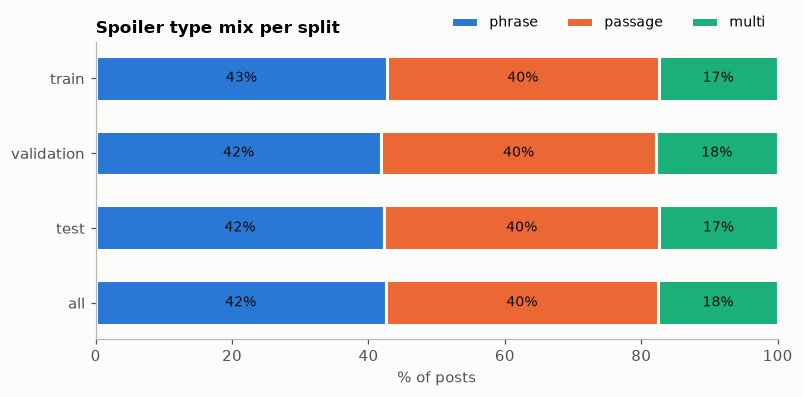

In [7]:
counts = pd.crosstab(df["split"], df["type"]).reindex(index=SPLITS, columns=TYPES)
counts.loc["all"] = counts.sum()
shares = counts.div(counts.sum(axis=1), axis=0).mul(100).round(1)
display(pd.concat({"posts": counts, "% of split": shares}, axis=1))
stacked_shares(counts, "Spoiler type mix per split")

### Platforms

Posts come from Twitter, Reddit and Facebook. Here's the platform mix per split, then the type mix per platform. The second one matters if we try the cross-platform idea (direction D): if platforms have very different type mixes, a drop in score across platforms could just be label shift rather than a real generalization gap.

platform,facebook,reddit,twitter,all
split,,,,
train,520,1150,1530,3200
validation,130,303,367,800
test,174,344,482,1000
all,824,1797,2379,5000


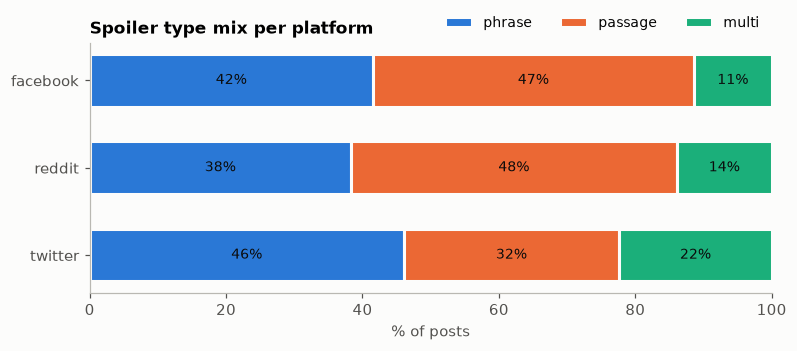

In [8]:
display(pd.crosstab(df["split"], df["platform"], margins=True, margins_name="all").reindex(SPLITS + ["all"]))
stacked_shares(pd.crosstab(df["platform"], df["type"]), "Spoiler type mix per platform")

### Provenance

Every post records who published the original spoiler (`spoilerPublisher`), and most also keep the spoiler text that person wrote (`humanSpoiler`). The `spoiler` field we train on is the span the annotators copied out of the article, while `humanSpoiler` is free text written by a human. It isn't part of the task, but it could serve as an abstractive reference if we ever evaluate generated spoilers. Publisher names come in different casings, so we lowercase them before counting.

In [9]:
display(df["publisher"].str.lower().fillna("(missing)").value_counts().head(10).to_frame("posts"))

has_human = df["human_spoiler"].fillna("").str.strip().ne("")
print("posts with a humanSpoiler, per split:")
print(has_human.groupby(df["split"]).agg(["sum", "mean"]).reindex(SPLITS).round(3).to_string())

,posts
publisher,
savedyouaclick,2107
huffpospoilers,1270
(missing),795
stop clickbait - lifestyle,170
stop clickbait - science,133
stop clickbait - entertainment,106
stop clickbait - gaming,86
stop clickbait - world news,76
stop clickbait - wtf,60


posts with a humanSpoiler, per split:
             sum   mean
split                  
train       2686  0.839
validation   676  0.845
test         842  0.842


A few side-by-side examples of the extracted spoiler versus the human-written one.

In [10]:
for row in df[has_human].sample(6, random_state=0).itertuples():
    print(f"[{row.type}] {row.post}")
    print(f"    extracted: {' | '.join(row.spoilers)}")
    print(f"    human:     {row.human_spoiler}\n")

[passage] Joanna Gaines Just Shared the Most Brilliant Decorating Trick Ever
    extracted: Instead of tossing leftover basil, she pops the kitchen staple into a bouquet for extra fullness, with the added bonus of a fresh scent.
    human:     She adds basil to her flower arrangements to add fullness (Not pictured in the article photo) #StopClickBait

[phrase] Jonas Blue reveals which international superstar he used to work in a pub with
    extracted: Sam Smith
    human:     Sam Smith

[passage] How 15 Minutes Could Change Your Sex Life
    extracted: 15 minutes of post-coitus cuddling boosts relationship satisfaction.
    human:     15 minutes of post-sex cuddling strengthens relationships. #StopClickBait

[passage] Officials Urge Calm as Protests Take a Turn
    extracted: A video of Mr. Boyd’s shooting, captured by an officer’s helmet camera and released by the Albuquerque Police, fueled the latest protests, most dramatically a march on Sunday that devolved from a peaceful demonst

## 5. Duplicates and leakage between splits

First the obvious checks: are the ids unique, and does the same post text or the same article show up more than once? We compare post texts after lowercasing and collapsing whitespace, and articles by their full paragraph text (URLs are missing for about 750 posts, so they're a weaker key).

In [11]:
print("duplicate uuids:  ", df["uuid"].duplicated().sum())
print("duplicate postIds:", raw["postId"].duplicated().sum())

df["post_key"] = df["post"].str.lower().map(lambda s: " ".join(s.split()))
df["article_key"] = df["paragraphs"].map(lambda ps: hash("\n".join(ps)))

repeated = df[df["post_key"].duplicated(keep=False)]
print(f"\n{len(repeated)} posts share their text with at least one other post "
      f"({repeated['post_key'].nunique()} distinct texts)")
print(f"{df['article_key'].duplicated(keep=False).sum()} posts share their article text with another post")
print(f"{df['url'].isna().sum()} posts have no URL")

duplicate uuids:   0
duplicate postIds: 0

91 posts share their text with at least one other post (44 distinct texts)
78 posts share their article text with another post
746 posts have no URL


The more important question is overlap *between* splits, since anything shared between train and test inflates test scores. Each cell counts distinct keys that appear in both splits.

In [12]:
def shared_between(key, a, b):
    in_a = set(df.loc[df["split"] == a, key].dropna())
    in_b = set(df.loc[df["split"] == b, key].dropna())
    return len(in_a & in_b)


pairs = [("train", "validation"), ("train", "test"), ("validation", "test")]
pd.DataFrame(
    {name: [shared_between(key, a, b) for a, b in pairs]
     for name, key in [("same post text", "post_key"), ("same article text", "article_key"), ("same URL", "url")]},
    index=[f"{a} / {b}" for a, b in pairs],
)

,same post text,same article text,same URL
train / validation,9,9,1
train / test,10,11,1
validation / test,3,1,0


Here are the posts whose text appears in more than one split, with a flag for whether all copies point at the same article. If the articles differ, it's a generic headline being reused (not a real leak); if they're the same, it's a true duplicate.

In [13]:
cross = df.groupby("post_key").filter(lambda g: g["split"].nunique() > 1)
cross = cross.assign(same_article=cross.groupby("post_key")["article_key"].transform("nunique").eq(1))
print(f"{cross['post_key'].nunique()} post texts appear in more than one split; "
      f"{cross.drop_duplicates('post_key')['same_article'].sum()} of them always point at the same article")
cross.sort_values(["post_key", "split"])[["split", "type", "post", "spoilers", "same_article"]]

22 post texts appear in more than one split; 10 of them always point at the same article


,split,type,post,spoilers,same_article
1533,train,multi,10 things you need to know before the opening bell,"[The Fed has its eyes on Trump, The British economy is ""exceeding all expectations."", Bitcoin surrenders most of its...",False
2165,train,multi,10 things you need to know before the opening bell,"[The World Bank says global growth will pick up slightly in 2017., US oil output is expected to rise in 2017 and 201...",False
2287,train,multi,10 things you need to know before the opening bell,"[Friday is jobs day in America., A new king of auto sales has been throned in China., Australia's first recession in...",False
3370,validation,multi,10 things you need to know before the opening bell,"[The Fed is expected to hike rates, The Netherlands is going to the polls, Oil is making a comeback, An early Twitte...",False
3431,validation,multi,10 things you need to know before the opening bell,"[US stocks are at all-time highs., The ECB meets on Thursday., China's economy is bouncing back., Japan's Final Q3 G...",False
4041,test,multi,17 badass historical LGBT women who gave absolutely no fucks,"[1. Tallulah Bankhead, 2. Anne Lister, 3. Gladys Bentley, 4. Hannah Snell, 5. Marion Barbara ""Joe"" Carstairs]",True
2131,train,multi,17 badass historical LGBT women who gave absolutely no fucks,"[1. Tallulah Bankhead, 2. Anne Lister, 3. Gladys Bentley, 4. Hannah Snell, 5. Marion Barbara]",True
4840,test,passage,Apple's New App: Can Deep Breathing Lower Stress?,"[Deep breathing lowers heart rate and reduces levels of stress hormones, according to the NCCIH]",False
821,train,passage,Apple's New App: Can Deep Breathing Lower Stress?,[Deep breathing lowers heart rate and reduces levels of stress hormones],False
1939,train,passage,Are You Reading The Wrong Books? What Science Is Saying About Fiction Readers,[readers of fiction are more empathetic towards others],True


## 6. Posts

### Post length

The post plays the role of the question in our QA setup. Short posts give the model very little to go on, so we want to know how much text it actually gets. Word counts here use a plain whitespace split, which is fine for comparing groups.

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
phrase,2125.0,10.8,3.3,2.0,8.0,11.0,13.0,23.0
passage,1999.0,10.7,3.7,1.0,8.0,11.0,13.0,26.0
multi,876.0,10.9,3.4,3.0,8.0,10.0,13.0,28.0


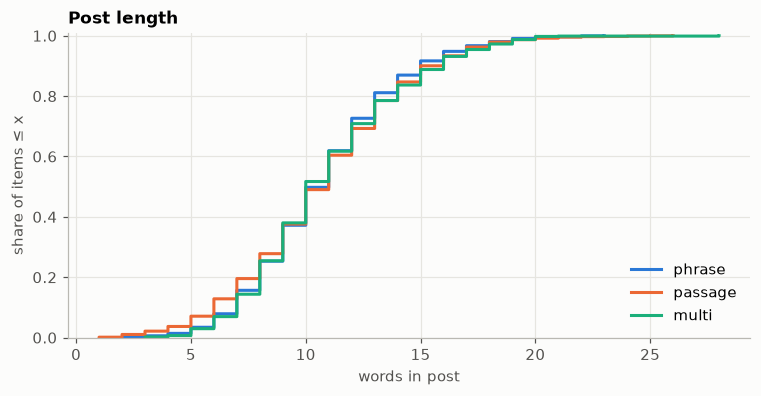

In [14]:
def n_words(text):
    return len(text.split())


df["post_words"] = df["post"].map(n_words)
display(df.groupby("type")["post_words"].describe().reindex(TYPES).round(1))
plot_ecdf(df, "post_words", "Post length", "words in post")

### How posts are phrased

Clickbait hides the key information behind words like "this", "these" or "here's why". Below are the most common first words of posts, split by type, and then the share of posts per type that contain a few cue words. If a cue is much more common in one type, the type classifier should pick it up easily.

In [15]:
first_word = df["post"].str.lower().str.extract(r"^\W*([\w'’]+)")[0]
(pd.crosstab(first_word, df["type"])[TYPES]
   .assign(total=lambda t: t.sum(axis=1))
   .sort_values("total", ascending=False)
   .head(15))

type,phrase,passage,multi,total
0,,,,
the,247,144,81,472
this,222,135,60,417
why,30,143,34,207
how,36,88,45,169
you,97,51,13,161
what,36,67,25,128
here's,49,42,14,105
is,16,67,7,90
a,40,35,15,90


In [16]:
CUES = {
    "contains a digit": r"\d",
    "why": r"\bwhy\b",
    "how": r"\bhow\b",
    "what": r"\bwhat\b",
    "who": r"\bwho\b",
    "this / these": r"\b(?:this|these)\b",
    "here's / here are": r"\bhere(?:['’]s| is| are)\b",
    "plural list noun": r"\b(?:things|ways|reasons|tips|facts|signs|foods|times|places|people)\b",
    "question mark": r"\?",
}
post_lower = df["post"].str.lower()
cue_share = pd.DataFrame({
    cue: post_lower.str.contains(pattern, regex=True).groupby(df["type"]).mean().mul(100)
    for cue, pattern in CUES.items()
}).T[TYPES].round(1)
cue_share.rename_axis("% of posts that contain...")

type,phrase,passage,multi
% of posts that contain...,,,
contains a digit,12.5,12.9,40.8
why,3.3,14.3,8.6
how,7.5,8.9,9.9
what,9.4,13.9,9.7
who,5.2,1.5,3.7
this / these,25.9,19.0,24.5
here's / here are,4.1,6.2,6.8
plural list noun,3.4,3.1,20.1
question mark,10.0,20.5,8.3


### Explicit counts in posts (direction B)

Many multi posts promise a number of items ("5 foods that..."). Here we pull the first count-like number out of each post and compare it with the number of gold spoiler spans. This decides whether reading k from the post could beat a fixed or tuned k.

What counts as "count-like": a 1-3 digit number that isn't money, a percentage, a decimal or part of a date like 9/11, or a number word from two to twenty. "One" is left out on purpose because it's usually not a count ("this one trick", "one of the best"). Four-digit numbers like years never match. The rule is still noisy (ages, "24 hours"), so treat the numbers as approximate.

In [17]:
NUMBER_WORDS = {w: i for i, w in enumerate(
    "zero one two three four five six seven eight nine ten eleven twelve thirteen "
    "fourteen fifteen sixteen seventeen eighteen nineteen twenty".split())}
COUNT_WORDS = "|".join(w for w, i in NUMBER_WORDS.items() if i >= 2)
COUNT_RE = re.compile(
    r"(?<![$£€\d.,:/])\b(\d{1,3})\b(?![.,:/]?\d|\s*%|\s*percent)"
    rf"|\b({COUNT_WORDS})\b",
    re.IGNORECASE,
)


def post_count(text):
    # First count-like number in the post, or None.
    m = COUNT_RE.search(text)
    if m is None:
        return None
    return int(m.group(1)) if m.group(1) else NUMBER_WORDS[m.group(2).lower()]


df["post_count"] = df["post"].map(post_count).astype("Int64")
(df.groupby("type")["post_count"].apply(lambda s: s.notna().mean() * 100)
   .reindex(TYPES).round(1).to_frame("% of posts with a count-like number"))

,% of posts with a count-like number
type,
phrase,9.1
passage,9.2
multi,40.6


Now just the multi posts: how often there is a count, how often it equals the number of gold spans, and the full table of count in post (rows) against number of gold spans (columns).

In [18]:
multi = df[df["type"] == "multi"]
counted = multi[multi["post_count"].notna()]
print(f"multi posts: {len(multi)}")
print(f"  with a count-like number: {len(counted)} ({len(counted) / len(multi):.0%})")
print(f"  where that number equals the number of gold spans: {(counted['post_count'] == counted['n_spans']).mean():.0%}")

order = [str(i) for i in range(1, 10)] + ["10+"]
bucket = pd.Categorical(counted["post_count"].map(lambda v: str(v) if v < 10 else "10+"), categories=order)
table = pd.crosstab(bucket, counted["n_spans"], rownames=["count in post"], colnames=["gold spans"])
table.loc[table.sum(axis=1) > 0]

multi posts: 876
  with a count-like number: 356 (41%)
  where that number equals the number of gold spans: 23%


gold spans,1,2,3,4,5,6,10,12
count in post,,,,,,,,
1,0,4,0,1,4,0,0,0
2,1,14,2,2,2,0,0,0
3,1,6,19,0,1,0,0,0
4,0,2,0,7,3,1,0,0
5,0,2,3,0,40,0,0,1
6,0,1,0,0,14,2,0,0
7,0,2,1,2,18,0,0,0
8,0,2,0,0,15,0,0,0
9,0,0,0,0,16,0,0,0


The 5 column looks suspiciously full. If annotators stopped at five items, posts promising more than five should mostly have exactly five spans. Let's check.

In [19]:
over_five = counted[counted["post_count"] > 5]
print(f"multi posts promising more than 5 items: {len(over_five)}")
over_five["n_spans"].value_counts().sort_index().to_frame("posts").rename_axis("gold spans")

multi posts promising more than 5 items: 240


,posts
gold spans,
2,17
3,4
4,5
5,208
6,5
10,1


So what should k be? Using **train multi posts only**, here's how often a few simple rules predict exactly the right number of spans. "Exact k" isn't our metric, but it's a quick way to compare rules before any model exists.

In [20]:
train_multi = multi[multi["split"] == "train"]
gold_k = train_multi["n_spans"]
mode_k = int(gold_k.mode()[0])
pc = train_multi["post_count"]

rules = {
    f"always {mode_k} (most common)": pd.Series(mode_k, index=train_multi.index),
    "always 2": pd.Series(2, index=train_multi.index),
    f"post count, else {mode_k}": pc.fillna(mode_k),
    f"min(post count, 5), else {mode_k}": pc.clip(upper=5).fillna(mode_k),
}
pd.Series({name: (k == gold_k).mean() * 100 for name, k in rules.items()}).round(1).to_frame("% exact k (train multi)")

,% exact k (train multi)
always 5 (most common),44.5
always 2,37.4
"post count, else 5",25.4
"min(post count, 5), else 5",47.8


## 7. Articles

### Article size

How long are the linked articles, in paragraphs and words? Length matters twice: the QA model has to slide a window across long articles, and more text means more places to pick a wrong span. `p90` is the 90th percentile.

title_words                 n_paragraphs                  article_words                      
             median  mean   p90 max       median  mean   p90  max        median   mean     p90    max
type                                                                                                 
phrase         11.0  11.1  15.0  29          9.0  11.8  23.0  265         310.0  429.5   850.6  13188
passage        11.0  11.2  16.0  33         10.0  13.2  26.0  116         354.0  511.1  1011.0  14059
multi          11.0  11.4  16.0  30         16.0  22.8  46.0  249         544.5  751.5  1470.5  11641

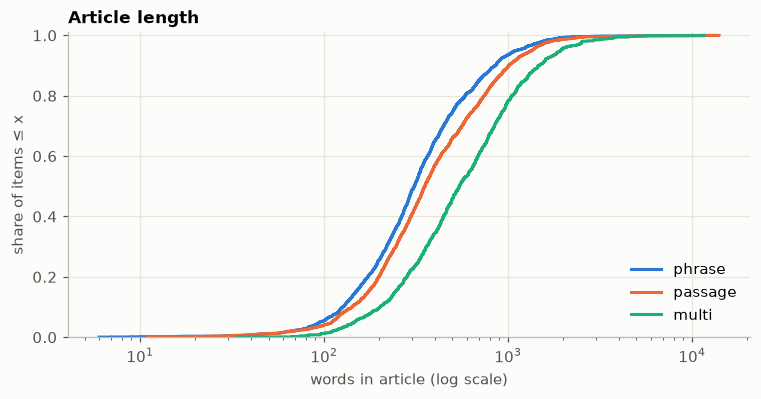

In [21]:
def p90(s):
    return s.quantile(0.9)


df["n_paragraphs"] = df["paragraphs"].map(len)
df["article_words"] = df["paragraphs"].map(lambda ps: sum(n_words(p) for p in ps))
df["title_words"] = df["title"].map(n_words)

display(df.groupby("type")[["title_words", "n_paragraphs", "article_words"]]
          .agg(["median", "mean", p90, "max"]).reindex(TYPES).round(1))
plot_ecdf(df, "article_words", "Article length", "words in article (log scale)", logx=True)

### Length in RoBERTa tokens

Word counts underestimate what the model sees, so here we tokenize with the real tokenizer. The context we'll give the QA model is the title followed by the paragraphs, one per line. Putting the title first keeps the spoilers that live in the title (paragraph `-1`) extractable. This takes a few seconds.

In [22]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm complains when ipywidgets isn't installed

from transformers import AutoTokenizer
from transformers.utils import logging as hf_logging

hf_logging.set_verbosity_error()  # hides the "longer than 512 tokens" warning; long inputs are expected here
tokenizer = AutoTokenizer.from_pretrained("roberta-base")


def build_context(title, paragraphs):
    return "\n".join([title, *paragraphs])


def n_tokens(text):
    return len(tokenizer(text, add_special_tokens=False)["input_ids"])


df["context"] = [build_context(t, ps) for t, ps in zip(df["title"], df["paragraphs"])]
df["post_tokens"] = df["post"].map(n_tokens)
df["context_tokens"] = df["context"].map(n_tokens)
df[["post_tokens", "context_tokens"]].describe().round(1)

,post_tokens,context_tokens
count,5000.0,5000.0
mean,13.9,700.2
std,4.9,879.9
min,2.0,14.0
25%,10.0,309.0
50%,13.0,486.0
75%,17.0,854.0
max,41.0,33563.0


How much of that fits in one window? Our baseline uses the SQuAD defaults: 384 tokens per window with a 128-token overlap (stride). Each window holds `<s> post </s></s> context </s>`, so the room for article text is 384 minus the post length minus 4 special tokens. From that we estimate how many windows each example needs, which roughly sets training and inference cost.

,median_tokens,p90_tokens,pct_over_384,pct_over_512,median_windows,max_windows
type,,,,,,
phrase,423.0,1132.6,56.7,38.4,2.0,78
passage,478.0,1333.0,63.2,46.1,2.0,139
multi,742.5,1977.5,81.2,69.1,3.0,69


total windows over train: 9,349 (for 3,200 posts)


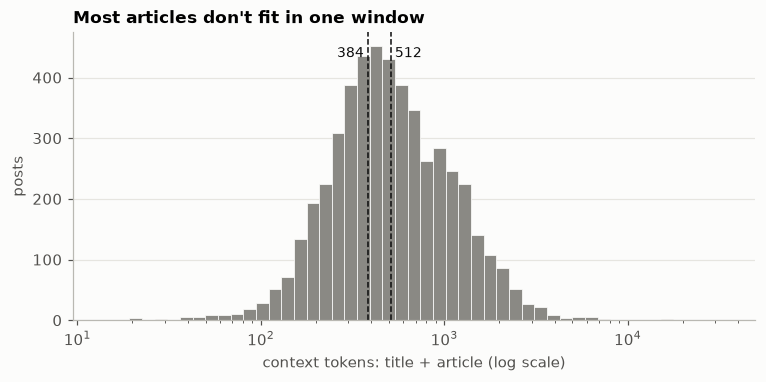

In [23]:
MAX_LEN, STRIDE = 384, 128
room = MAX_LEN - df["post_tokens"] - 4
df["n_windows"] = 1 + np.ceil((df["context_tokens"] - room).clip(lower=0) / (room - STRIDE)).astype(int)

display(df.groupby("type").agg(
    median_tokens=("context_tokens", "median"),
    p90_tokens=("context_tokens", p90),
    pct_over_384=("context_tokens", lambda s: (s > 384).mean() * 100),
    pct_over_512=("context_tokens", lambda s: (s > 512).mean() * 100),
    median_windows=("n_windows", "median"),
    max_windows=("n_windows", "max"),
).reindex(TYPES).round(1))
print(f"total windows over train: {df.loc[df['split'] == 'train', 'n_windows'].sum():,} "
      f"(for {(df['split'] == 'train').sum():,} posts)")

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.logspace(np.log10(df["context_tokens"].min()), np.log10(df["context_tokens"].max()), 50)
ax.hist(df["context_tokens"], bins=bins, color=GRAY, edgecolor=SURFACE, linewidth=0.5)
ax.set_xscale("log")
for limit, align in ((384, "right"), (512, "left")):
    ax.axvline(limit, color=INK, linewidth=1, linestyle="--")
    ax.text(limit, ax.get_ylim()[1] * 0.95, f" {limit} ", ha=align, va="top", fontsize=9, color=INK)
ax.set_xlabel("context tokens: title + article (log scale)")
ax.set_ylabel("posts")
ax.set_title("Most articles don't fit in one window", loc="left")
plt.show()

## 8. Spoilers

### Number of spans

Phrase and passage spoilers should always be a single span, and multi spoilers should have several. Let's confirm.

In [24]:
pd.crosstab(df["type"], df["n_spans"]).reindex(TYPES)

n_spans,1,2,3,4,5,6,8,10,12
type,,,,,,,,,
phrase,2125,0,0,0,0,0,0,0,0
passage,1999,0,0,0,0,0,0,0,0
multi,30,312,79,44,396,11,1,2,1


A handful of multi posts have only one span, which contradicts the type definition. Here are some, to see whether they look mislabeled or whether the single span holds a whole list.

In [25]:
single_multi = df[(df["type"] == "multi") & (df["n_spans"] == 1)]
print(f"{len(single_multi)} multi posts have a single span "
      f"({single_multi['split'].value_counts().reindex(SPLITS).to_dict()})")
single_multi[["split", "post", "spoilers"]].head(8)

30 multi posts have a single span ({'train': 20, 'validation': 4, 'test': 6})


,split,post,spoilers
400,train,New on @Medium: What it's like when your children never grow up,"[""We can’t just drop everything and go out for dinner with our friends, we can’t go on trips, we’ve never been on a ..."
455,train,Should this military grade flashlight be banned?,"[You know how after someone takes a picture of you at night with the flash on, it takes like 3 minutes to see proper..."
737,train,George who? @StacyKeibler has reportedly moved on to millionaire businessman,"[The 33-year-old ex-girlfriend of George Clooney became a single lady in June, but is reportedly dating Jared Pobre,..."
807,train,This Is How You Can Make Your Clogged Pores Disappear Using ONE Cupboard Ingredient,"[In short, you have to mix the baking soda with water to form a paste.]"
969,train,CNBC host makes wildly offensive comments,[Joe Kernen]
1545,train,Britain's Got Talent Star Banned For This Death-Defying Act,"[I think most people would back the producers on their decision to ban live filming, though – a sword-swallowing act..."
1585,train,Why UK surgeon cannot forget this girl,[a gravely injured baby girl called Maram]
1642,train,You’ll never guess what happened when three junkies tried to rob this former prizefighter,"[The chaotic scenes were reported to have continued until local police arrived on the scene, one whole hour and a ha..."


### Spoiler length

Phrase and passage are mostly a length distinction by definition: a phrase is a few words, a passage is a sentence or more. We build a span-level table (one row per spoiler span, so multi posts contribute several rows) and measure each span in words. We also keep the total spoiler length per post.

7,277 spans in total


words per span                          words per post (all spans)             
                  mean   25%   50%   75%    max                       mean   50%    max
type                                                                                   
phrase             2.5   2.0   2.0   3.0   11.0                        2.5   2.0   11.0
passage           21.1  11.0  17.0  27.0  174.0                       21.1  17.0  174.0
multi              8.0   2.0   5.0  10.0  117.0                       28.7  20.0  255.0

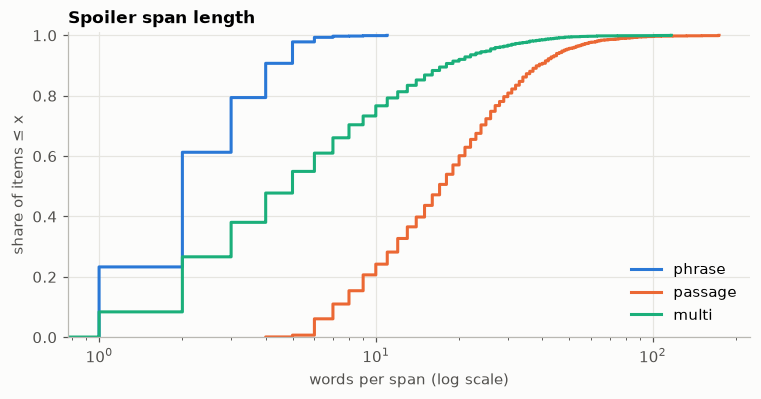

In [26]:
spans = (df[["split", "type", "uuid", "spoilers", "positions"]]
         .explode(["spoilers", "positions"])
         .rename(columns={"spoilers": "span", "positions": "position"})
         .reset_index(drop=True))
spans["span_words"] = spans["span"].map(n_words)
df["spoiler_words"] = df["spoilers"].map(lambda ss: sum(n_words(s) for s in ss))
print(f"{len(spans):,} spans in total")

display(pd.concat({
    "words per span": spans.groupby("type")["span_words"].describe()[["mean", "25%", "50%", "75%", "max"]],
    "words per post (all spans)": df.groupby("type")["spoiler_words"].describe()[["mean", "50%", "max"]],
}, axis=1).reindex(TYPES).round(1))
plot_ecdf(spans, "span_words", "Spoiler span length", "words per span (log scale)", logx=True)

How cleanly does length alone separate phrase from passage? On **train only**, we find the word-count cut-off that best separates phrase from passage spoilers if we knew the gold spoiler, then check the same cut-off on validation. This isn't a usable classifier (at prediction time we don't have the spoiler), but it shows how close the labels are to a length rule. It also hints that the length of a *predicted* span could be a useful feature for the type classifier.

In [27]:
train_pp = df[(df["split"] == "train") & df["type"].isin(["phrase", "passage"])]
val_pp = df[(df["split"] == "validation") & df["type"].isin(["phrase", "passage"])]


def threshold_accuracy(data, cutoff):
    return ((data["spoiler_words"] <= cutoff) == data["type"].eq("phrase")).mean()


accuracy = {cutoff: threshold_accuracy(train_pp, cutoff) for cutoff in range(1, 41)}
best = max(accuracy, key=accuracy.get)
print(f"best rule on train: 'phrase if the spoiler has <= {best} words' -> {accuracy[best]:.1%}")
print(f"same rule on validation: {threshold_accuracy(val_pp, best):.1%}")

phrase_words = train_pp.loc[train_pp["type"] == "phrase", "spoiler_words"]
passage_words = train_pp.loc[train_pp["type"] == "passage", "spoiler_words"]
print(f"train phrase spoilers longer than {best} words: {(phrase_words > best).mean():.1%}")
print(f"train passage spoilers of {best} words or fewer: {(passage_words <= best).mean():.1%}")

best rule on train: 'phrase if the spoiler has <= 5 words' -> 98.5%
same rule on validation: 99.2%
train phrase spoilers longer than 5 words: 2.2%
train passage spoilers of 5 words or fewer: 0.8%


## 9. Spoiler positions

### Can we trust `spoilerPositions`?

Each span's position is `[[start_paragraph, start_char], [end_paragraph, end_char]]`, end exclusive, with paragraph `-1` meaning the title. We rebuild every span from its position and compare it with the gold text. Each span lands in one of four buckets: an exact match, a span that crosses paragraphs, a same-paragraph offset that points at different text, or a malformed position. This is the main thing our offset converter has to handle.

In [28]:
def position_status(title, paragraphs, span, position):
    if len(position) != 2:
        return "malformed position"
    (p1, c1), (p2, c2) = position
    if p1 != p2:
        return "crosses paragraphs"
    if not -1 <= p1 < len(paragraphs):
        return "paragraph out of range"
    source = title if p1 == -1 else paragraphs[p1]
    return "exact" if source[c1:c2] == span else "points at other text"


lookup = df.set_index("uuid")
spans["status"] = [
    position_status(lookup.at[u, "title"], lookup.at[u, "paragraphs"], s, p)
    for u, s, p in zip(spans["uuid"], spans["span"], spans["position"])
]
pd.crosstab(spans["status"], spans["type"], margins=True, margins_name="all")[TYPES + ["all"]]

type,phrase,passage,multi,all
status,,,,
crosses paragraphs,1,38,50,89
exact,2122,1959,3080,7161
malformed position,0,1,0,1
points at other text,2,1,23,26
all,2125,1999,3153,7277


Some examples from each problem bucket, showing the position, the gold text, and what the position actually points at in its start paragraph. For spans that cross paragraphs we also check how often the start offset is past the end of its paragraph, which would mean those offsets aren't per-paragraph at all.

In [29]:
def text_at(title, paragraphs, position):
    (p1, c1) = position[0]
    source = title if p1 == -1 else paragraphs[p1]
    c2 = position[1][1] if len(position) == 2 and position[1][0] == p1 else c1 + 100
    return source[c1:c2]


for status in ["crosses paragraphs", "points at other text", "malformed position"]:
    print(f"--- {status} ---")
    for row in spans[spans["status"] == status].head(3).itertuples():
        pointed = text_at(lookup.at[row.uuid, "title"], lookup.at[row.uuid, "paragraphs"], row.position)
        print(f"  position:  {row.position}")
        print(f"  gold:      {row.span[:100]!r}")
        print(f"  points at: {pointed[:100]!r}\n")

crossing = spans[spans["status"] == "crosses paragraphs"]
past_end = sum(
    pos[0][1] > len(lookup.at[u, "title"] if pos[0][0] == -1 else lookup.at[u, "paragraphs"][pos[0][0]])
    for u, pos in zip(crossing["uuid"], crossing["position"])
)
print(f"crossing spans whose start offset is past the end of the start paragraph: {past_end} / {len(crossing)}")

--- crosses paragraphs ---
  position:  [[8, 709], [9, 815]]
  gold:      'just that famous VW badge ... ... which flips open when the car is in reverse to reveal the hidden c'
  points at: ''

  position:  [[0, 1], [1, 12]]
  gold:      'Schwarmerei'
  points at: 'eltschmerz'

  position:  [[3, 480], [5, 852]]
  gold:      "Yankees have not scored a run since the ninth inning of Wednesday's game. On Thursday, they were bla"
  points at: ''

--- points at other text ---
  position:  [[31, 3], [31, 23]]
  gold:      'Cholula Chili Garlic'
  points at: ' Cholula Chili Garli'

  position:  [[3, 745], [3, 762]]
  gold:      'Amazonian look'
  points at: ''

  position:  [[-1, 0], [-1, 10]]
  gold:      'In-Flight Internet'
  points at: 'One In Ten'

--- malformed position ---
  position:  [[4, 836]]
  gold:      'at level 256, there’s only enough memory in the game for the left-half of the board. The right-half '
  points at: ''

crossing spans whose start offset is past the end of the sta

### Fallback: find the span by its text

For spans whose positions don't work, we try to find the gold text directly in the context (title + paragraphs), after collapsing whitespace on both sides. Three outcomes:
- **found once**: the position is recoverable;
- **found 2+ times**: recoverable, but we can't tell which copy was meant (the first copy is a fine training target, since scoring is text-based);
- **not found**: the gold spoiler isn't a verbatim piece of the article, so an extractive model can't produce it exactly.

We record the number of occurrences for every span, not just the broken ones, because we reuse it further down.

In [30]:
def squash(text):
    return " ".join(text.split())


def count_occurrences(needle, haystack):
    if not needle:
        return 0
    count, start = 0, haystack.find(needle)
    while start != -1:
        count += 1
        start = haystack.find(needle, start + 1)
    return count


squashed_context = dict(zip(df["uuid"], df["context"].map(squash)))
spans["occurrences"] = [count_occurrences(squash(s), squashed_context[u]) for s, u in zip(spans["span"], spans["uuid"])]

found = spans["occurrences"].clip(upper=2).map({0: "not found", 1: "found once", 2: "found 2+ times"})
display(pd.crosstab(spans["status"], found)[["found once", "found 2+ times", "not found"]])

spans["usable"] = spans["status"].eq("exact") | spans["occurrences"].ge(1)
post_usable = spans.groupby("uuid")["usable"].all()
print(f"spans usable for extractive training (exact position or found by text): {spans['usable'].mean():.2%}")
print(f"posts where every span is usable: {post_usable.mean():.2%} ({(~post_usable).sum()} posts are not)")

occurrences,found once,found 2+ times,not found
status,,,
crosses paragraphs,85,0,4
exact,5821,1338,2
malformed position,1,0,0
points at other text,12,2,12


spans usable for extractive training (exact position or found by text): 99.78%
posts where every span is usable: 99.68% (16 posts are not)


And what do the spans that can't be found look like? Usually the annotator's text differs slightly from the article (accents, punctuation, words merged across paragraphs).

In [31]:
for row in spans[spans["occurrences"] == 0].head(6).itertuples():
    print(f"[{row.type} | {row.status}] gold: {row.span[:110]!r}")

[multi | crosses paragraphs] gold: 'Schwarmerei'
[multi | points at other text] gold: 'Amazonian look'
[multi | points at other text] gold: '4In the Czech Republic, unmarried girls are supposed to throw a shoe over their shoulder in the direction of t'
[multi | points at other text] gold: 'Apple Jacks has the most popular food dyes known to cause behavioral problems in children'
[multi | points at other text] gold: 'We had a swingers group stay at the hotel for a few nights. They had a rave going on up on the second floor, t'
[multi | points at other text] gold: '"What I always love is people say, \'Well, it\'s you folks\' fault in the media.\' No! It\'s the President of the U'


### Where spoilers sit in the article

For each post we take the earliest paragraph that holds a spoiler span, using only spans with exact positions. If spoilers cluster at the start, a "first paragraph" baseline will be strong and truncating long articles costs little. Paragraphs are counted from 1 here to read naturally.

type,phrase,passage,multi
first spoiler paragraph,,,
title,3.2,1.7,0.6
1st,33.1,17.5,22.9
2nd,24.9,19.1,21.2
3rd,13.2,14.6,14.2
4th-5th,12.4,19.2,20.0
6th-10th,8.8,17.7,14.3
11th+,4.3,10.2,6.8


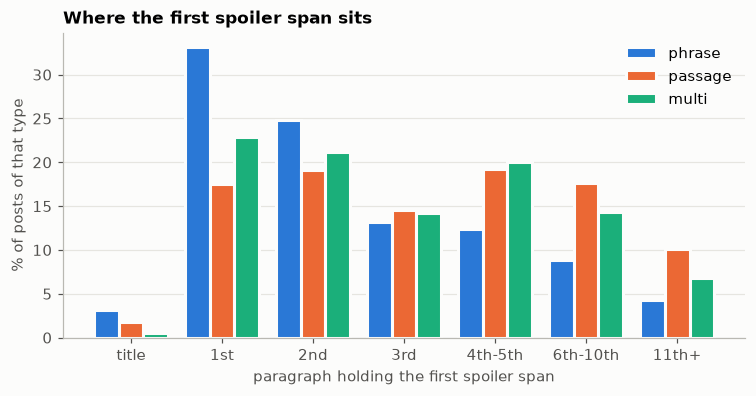

In [32]:
exact = spans[spans["status"] == "exact"].copy()
exact["para"] = exact["position"].map(lambda p: p[0][0])
exact["char"] = exact["position"].map(lambda p: p[0][1])

first_para = exact.groupby("uuid")["para"].min()
posts_pos = lookup.loc[first_para.index, ["type", "n_paragraphs"]].assign(first_para=first_para)


def para_bucket(p):
    if p == -1:
        return "title"
    if p <= 2:
        return ["1st", "2nd", "3rd"][p]
    if p <= 4:
        return "4th-5th"
    if p <= 9:
        return "6th-10th"
    return "11th+"


BUCKETS = ["title", "1st", "2nd", "3rd", "4th-5th", "6th-10th", "11th+"]
where = pd.crosstab(posts_pos["first_para"].map(para_bucket), posts_pos["type"], normalize="columns")
where = where.reindex(index=BUCKETS, columns=TYPES).fillna(0).mul(100)
display(where.round(1).rename_axis("first spoiler paragraph"))

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(BUCKETS))
width = 0.27
for i, t in enumerate(TYPES):
    ax.bar(x + (i - 1) * width, where[t], width, color=TYPE_COLORS[t], edgecolor=SURFACE, linewidth=2, label=t)
ax.set_xticks(x, BUCKETS)
ax.set_xlabel("paragraph holding the first spoiler span")
ax.set_ylabel("% of posts of that type")
ax.set_title("Where the first spoiler span sits", loc="left")
ax.legend()
plt.show()

The same thing in relative terms: the first spoiler paragraph divided by the number of paragraphs (0 = top of the article, 1 = bottom). Title spoilers are left out here.

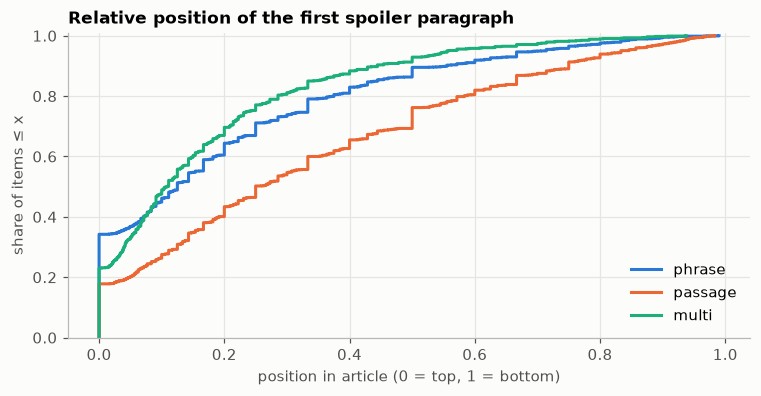

In [33]:
body = posts_pos[posts_pos["first_para"] >= 0]
body = body.assign(relative=body["first_para"] / body["n_paragraphs"])
plot_ecdf(body, "relative", "Relative position of the first spoiler paragraph", "position in article (0 = top, 1 = bottom)")

### How strong is the "first sentence" baseline?

The simple baseline in our proposal predicts the first sentence of the article. How often does that sentence contain a spoiler span? We cut the first paragraph at the first `.`, `!` or `?` followed by whitespace (crude, but good enough) and check whether any exact span lies entirely inside it. We also report the looser "any span in the first paragraph".

In [34]:
paragraphs_by_uuid = dict(zip(df["uuid"], df["paragraphs"]))


def first_sentence_end(paragraph):
    m = re.search(r"[.!?][\"'”’)]*\s", paragraph)
    return m.end() if m else len(paragraph)


def in_first_sentence(uuid, position):
    (p1, c1), (p2, c2) = position
    return p1 == 0 and p2 == 0 and c2 <= first_sentence_end(paragraphs_by_uuid[uuid][0])


exact["in_first_sentence"] = [in_first_sentence(u, p) for u, p in zip(exact["uuid"], exact["position"])]
exact["in_first_paragraph"] = exact["para"].eq(0)
(exact.groupby(["type", "uuid"])[["in_first_paragraph", "in_first_sentence"]].any()
      .groupby(level="type").mean().mul(100).reindex(TYPES).round(1)
      .rename(columns=lambda c: "% posts: span " + c.replace("_", " ")))

,% posts: span in first paragraph,% posts: span in first sentence
type,,
phrase,33.1,22.6
passage,17.5,9.7
multi,23.1,16.6


### Spoiler position in tokens

Even with sliding windows it's useful to know how many spoilers would be lost if we simply truncated the context. We convert each exact span's (paragraph, char) position to a character offset in the context string and then to a token index, using the tokenizer's offset mapping.

The `assert` in the loop is a check of the conversion itself: for every exact span, the converted offset has to point at exactly the gold text inside the context. This is the same conversion our QA preprocessing will need.

offset conversion checked on 7,161 spans, all exact


,% all spans lost at 384,% some span lost at 384,% all spans lost at 512,% some span lost at 512
type,,,,
phrase,7.1,7.1,4.0,4.0
passage,15.6,15.6,10.7,10.7
multi,9.9,47.6,6.6,35.6


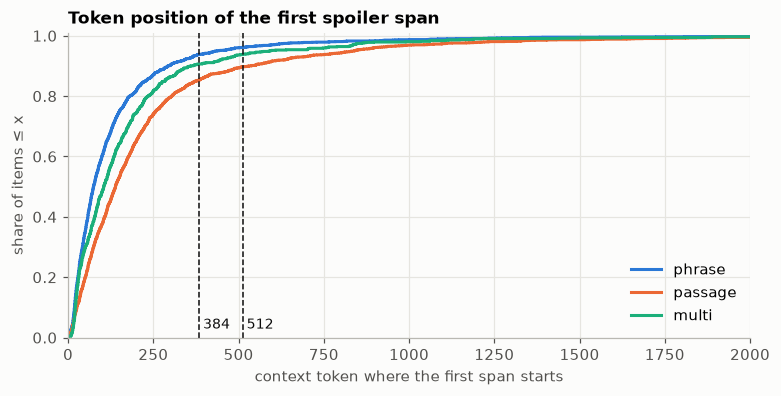

In [35]:
def context_char_offset(title, paragraphs, para, char):
    # Character offset of (para, char) inside build_context(title, paragraphs).
    if para == -1:
        return char
    return len(title) + 1 + sum(len(p) + 1 for p in paragraphs[:para]) + char


token_start = {}
for uuid, group in exact.groupby("uuid", sort=False):
    row = lookup.loc[uuid]
    offsets = tokenizer(row["context"], add_special_tokens=False, return_offsets_mapping=True)["offset_mapping"]
    starts = [s for s, _ in offsets]
    for idx, span, para, char in zip(group.index, group["span"], group["para"], group["char"]):
        start = context_char_offset(row["title"], row["paragraphs"], para, char)
        assert row["context"][start:start + len(span)] == span
        token_start[idx] = bisect_right(starts, start) - 1

exact["token_start"] = pd.Series(token_start)
exact = exact.join(lookup["post_tokens"], on="uuid")
print(f"offset conversion checked on {len(token_start):,} spans, all exact")

for limit in (384, 512):
    exact[f"cut_at_{limit}"] = exact["token_start"] >= limit - exact["post_tokens"] - 4

per_post = exact.groupby(["type", "uuid"]).agg(
    first_cut_384=("cut_at_384", "min"), any_cut_384=("cut_at_384", "max"),
    first_cut_512=("cut_at_512", "min"), any_cut_512=("cut_at_512", "max"),
)
display(per_post.groupby(level="type").mean().mul(100).reindex(TYPES).round(1)
        .rename(columns={"first_cut_384": "% all spans lost at 384", "any_cut_384": "% some span lost at 384",
                         "first_cut_512": "% all spans lost at 512", "any_cut_512": "% some span lost at 512"}))

first_tokens = exact.groupby("uuid").agg(type=("type", "first"), token_start=("token_start", "min"))
plot_ecdf(first_tokens, "token_start", "Token position of the first spoiler span",
          "context token where the first span starts", xlim=(0, 2000), vlines=(384, 512))

### Repeated spoiler strings

If the gold spoiler text appears several times in the article, the extractive label is ambiguous: training uses the annotated copy, but the model may well point at another one. That's harmless for text-based scoring but adds noise to training. Short phrase spoilers (names, numbers) should repeat the most.

In [36]:
repeats = spans["occurrences"].clip(upper=3).map({0: "0 (not verbatim)", 1: "1", 2: "2", 3: "3+"})
display(pd.crosstab(spans["type"], repeats, normalize="index").mul(100).round(1).reindex(TYPES)
          .rename_axis(columns="times the span occurs in the context"))
spans.sort_values("occurrences", ascending=False)[["type", "span", "occurrences"]].head(8)

times the span occurs in the context,0 (not verbatim),1,2,3+
type,,,,
phrase,0.0,55.9,18.6,25.5
passage,0.0,98.6,1.4,0.0
multi,0.6,87.5,7.3,4.6


,type,span,occurrences
6738,phrase,wingsuit,87
6061,phrase,the Patriots,47
1728,phrase,Nigeria,32
1426,phrase,work,28
239,phrase,fascia,27
2123,phrase,feminist,26
5210,phrase,slash,26
2865,phrase,mercury,23


### Structure of multi spoilers (direction B)

For structure-aware multi extraction we want to know whether multi spoilers look like list items. Using multi posts where every span has an exact position, we check whether the spans come in reading order, whether each sits in its own paragraph, whether they start at the beginning of a paragraph, whether the span text is numbered ("1.", "2)"), and how far apart the span paragraphs are.

In [37]:
NUMBERED_RE = re.compile(r"^\s*(?:#|No\.?\s*)?\(?\d{1,2}[.):\-]?\s")

complete_multi = (exact[exact["type"] == "multi"]
                  .groupby("uuid").filter(lambda g: len(g) == lookup.at[g.name, "n_spans"] and len(g) > 1))

rows = []
for uuid, g in complete_multi.groupby("uuid", sort=False):
    order = list(zip(g["para"], g["char"]))
    paras = sorted(set(g["para"]))
    gaps = np.diff(paras) if len(paras) > 1 else np.array([0])
    rows.append({
        "spans in reading order": order == sorted(order),
        "each span in its own paragraph": len(paras) == len(g),
        "every span starts a paragraph": g["char"].eq(0).all(),
        "every span text is numbered": g["span"].str.match(NUMBERED_RE).all(),
        "span paragraphs are consecutive": (gaps == 1).all(),
        "max gap between span paragraphs <= 3": gaps.max() <= 3,
    })
structure = pd.DataFrame(rows)
print(f"{len(structure)} multi posts with all spans exact and at least 2 spans")
structure.mean().mul(100).round(1).to_frame("% of those posts")

805 multi posts with all spans exact and at least 2 spans


,% of those posts
spans in reading order,92.9
each span in its own paragraph,76.3
every span starts a paragraph,40.1
every span text is numbered,24.2
span paragraphs are consecutive,20.0
max gap between span paragraphs <= 3,71.4


## 10. Word overlap between post and article

How far does plain word matching get us? For each post we score every paragraph by how many of the post's content words it contains, rank the paragraphs by that score (ties go to the earlier paragraph), and check whether the top 1 or top 3 holds a spoiler span. We compare this with simply taking the first paragraph(s). This gives a feel for how much the QA model can get from surface overlap, and it's a cheap baseline for passage spoilers. Only exact spans in the body (not the title) are used as targets.

In [38]:
STOPWORDS = set('''
a an the and or but if of to in on at by for with from as is are was were be been being this that these those
it its he she they them his her their you your we our i me my not no so than then there here what which who whom
why how when where will would can could should may might do does did have has had just about into over after
before up out more most very all any some one new get got make makes'''.split())


def content_words(text):
    return {w for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOPWORDS and len(w) > 1}


gold_paras = exact[exact["para"] >= 0].groupby("uuid")["para"].agg(set)
records = []
for uuid, gold in gold_paras.items():
    row = lookup.loc[uuid]
    post_words = content_words(row["post"])
    overlap = [len(post_words & content_words(p)) for p in row["paragraphs"]]
    ranked = sorted(range(len(overlap)), key=lambda i: (-overlap[i], i))
    records.append({
        "type": row["type"],
        "first paragraph": 0 in gold,
        "first 3 paragraphs": bool(gold & {0, 1, 2}),
        "word overlap, top 1": ranked[0] in gold,
        "word overlap, top 3": bool(gold & set(ranked[:3])),
    })

retrieval = pd.DataFrame(records)
retrieval.groupby("type").mean().mul(100).reindex(TYPES).round(1).rename_axis("% posts where the pick holds a spoiler")

,first paragraph,first 3 paragraphs,"word overlap, top 1","word overlap, top 3"
% posts where the pick holds a spoiler,,,,
phrase,34.2,73.6,37.6,70.9
passage,17.8,52.1,25.9,61.3
multi,23.1,58.7,26.2,52.2


## 11. Examples

Numbers only go so far, so here are a few random **train** examples per type: the post, the title, each spoiler span, and the text around it in the article with the span marked `[[like this]]`. Change the seed to see others.

In [39]:
def show_example(uuid):
    row = lookup.loc[uuid]
    print(f"[{row['type']} | {row['platform']} | {row['split']}]")
    print(f"POST:  {row['post']}")
    print(f"TITLE: {row['title']}")
    for span, position in zip(row["spoilers"], row["positions"]):
        print(f"  SPOILER: {span!r}")
        if position_status(row["title"], row["paragraphs"], span, position) == "exact":
            (p, c1), (_, c2) = position
            source = row["title"] if p == -1 else row["paragraphs"][p]
            where = "title" if p == -1 else f"paragraph {p + 1} of {len(row['paragraphs'])}"
            print(f"    in {where}: ...{source[max(0, c1 - 120):c1]}[[{source[c1:c2]}]]{source[c2:c2 + 120]}...")
    print()


rng = random.Random(7)
for t in TYPES:
    pool = df.loc[(df["type"] == t) & (df["split"] == "train"), "uuid"].tolist()
    print("=" * 40, t.upper(), "=" * 40)
    for uuid in rng.sample(pool, 3):
        show_example(uuid)

======================================== PHRASE ========================================
[phrase | twitter | train]
POST:  And the Miss America 2014 crown went to...
TITLE: Nina Davuluri, Miss New York, Wins Miss America 2014 Title (PHOTOS)
  SPOILER: 'Nina Davuluri, Miss New York'
    in paragraph 1 of 9: ...[[Nina Davuluri, Miss New York]], was crowned the new Miss America on Sunday night in Atlantic City, New Jersey....

[phrase | reddit | train]
POST:  How to pronounce LaCroix (if you're not an ass)
TITLE: How to pronounce LaCroix (if you're not an ass)
  SPOILER: '"La-CROY. It rhymes with ‘enjoy’."'
    in paragraph 17 of 23: ..., from the people at LaCroix themselves: [["La-CROY. It rhymes with ‘enjoy’."]] The answer , from the people at LaCroix themselves: "La-CROY. It rhymes with ‘enjoy’."...

[phrase | reddit | train]
POST:  The Embarrassingly Obvious Truth About Where Pine Nuts Come From
TITLE: The Embarrassingly Obvious Truth About Where Pine Nuts Come From
  SPOILER: 'pine 

## 12. Takeaways

Numbers are from the run above. Where a point affects a design decision, the decision is in **bold**.

**Data quality**
- The splits match the paper exactly (3,200 / 800 / 1,000 posts; 2,125 phrase, 1,999 passage, 876 multi), and every split has the same type mix (about 42 / 40 / 18%). The test set has gold labels, so **we use the official splits and don't need the validation-as-test fallback.**
- `spoilerPositions` are right for 98.4% of spans (7,161 of 7,277). The rest are 89 spans that cross paragraphs, whose offsets don't follow the per-paragraph format (79 of them start past the end of their paragraph), 26 that point at the wrong text, and 1 malformed position. Searching for the gold text recovers almost all of them: 99.8% of spans and 99.7% of posts are usable for extractive training, and only 16 posts have a span that isn't in the article verbatim. **Converter plan: use the position if it reproduces the gold text, otherwise search for the text, otherwise skip that example in training.**
- **Context = title + "\n" + paragraphs joined by "\n".** The offset conversion for that layout is verified: the assert in section 9 passes for all 7,161 exact spans. Putting the title first matters for the ~2% of posts whose spoiler is in the title.
- There's a small overlap between splits: 11 articles appear in both train and test, 9 in train and validation. It's tiny, but worth a sentence in the report, and we could drop those posts from train to be strict.
- Odd cases to know about: 30 multi posts have a single span (they read like passages), 3 posts have an empty title, and `humanSpoiler` texts contain hashtags like `#StopClickBait`.

**Spoiler types**
- Phrase vs passage is almost a pure length rule on the gold spoiler: "5 words or fewer = phrase" is right 98.5% of the time on train and 99.2% on validation. So the type classifier is really predicting how long the answer will be. **Idea worth trying: predict the type after extraction, using the length of the predicted span as a feature.**
- Post cues: posts with a digit (41% of multi vs about 13% of the others) or a plural list noun like "things" or "ways" (20% vs 3%) lean multi, and "why" and question marks lean passage. Post length is the same across types (median 10 to 11 words).
- Platforms differ: Twitter has twice the multi share of Facebook (22% vs 11%) and fewer passages (32% vs 47 to 48% on Facebook and Reddit). **For direction D, compare platforms per type, or the result will mostly reflect label shift.**

**Multi spoilers and direction B**
- 41% of multi posts contain a count-like number, but it equals the number of gold spans only 23% of the time. The main reason is that annotation seems capped at five spans: of 240 multi posts promising more than five items, 208 have exactly five.
- With the cap built in, "min(post count, 5), else 5" gets k exactly right for 47.8% of train multi posts, against 44.5% for "always 5". **Reading k from the post helps only a little on its own, so direction B needs the structure part too.**
- Structure: in 93% of multi posts (where every span has an exact position) the spans come in reading order, 76% have one span per paragraph, 40% have every span starting a paragraph, and 24% are explicitly numbered. Structure-aware extraction has something to work with, but list-shaped articles aren't the majority.

**Length and windows**
- Median context is 486 tokens, and 57 to 81% of articles (depending on type; multi is longest) don't fit in a 384-token window. **Sliding windows are required.** Train comes to about 9.3k windows of 384 tokens, which is fine on a T4.
- Truncating at 384 tokens instead would lose the spoiler for 7% of phrase and 16% of passage posts, and at least one span for 48% of multi posts.

**Where spoilers are, and what that says about baselines**
- Spoilers lean towards the top of the article. The first paragraph holds the first span for 33% of phrase, 18% of passage and 23% of multi posts, and the first three paragraphs for roughly half (passage) to three quarters (phrase).
- The first sentence contains a spoiler span only 10 to 23% of the time, so **the "first sentence" baseline is a low floor.** It's still worth keeping as our honest simple baseline.
- Word overlap with the post picks a spoiler paragraph slightly more often than "first paragraph" (top 1: 38 / 26 / 26% vs 34 / 18 / 23% for phrase / passage / multi). The QA model has to do a lot better than surface matching.
- Phrase spoilers repeat a lot: 44% occur two or more times in their context, some dozens of times ("wingsuit" appears 87 times). This makes start/end training labels noisy but doesn't matter for text-based scoring.

**For evaluation**
- 84% of posts have a `humanSpoiler` written by the original spoiler account. **If we evaluate generated spoilers, it's a ready-made second reference** (after stripping the hashtags).